# Análise de Vendas

Análise exploratória de dados obtidos através do Kaggle de uma loja de eletrônicos americana, com centenas de milhares de pedidos ao longo de 12 meses no ano de 2019. O objetivo é transformar dados brutos de vendas em respostas para perguntas de negócio, usando Python, Pandas e Matplotlib.

In [32]:
# bibliotecas

# !pip install pandas
# !pip install matplotlib

import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from itertools import combinations
from collections import Counter

## Mesclar todos os arquivos csv e salvar em um único DF

In [31]:
diretorio = Path('dados')
saida = Path('saida')
saida.mkdir(exist_ok=True)

arquivos = sorted(diretorio.glob('*.csv'))
df = pd.concat((pd.read_csv(a) for a in arquivos), ignore_index=True)

df.to_csv(saida / 'df_completo.csv', index=False)

print(f"Sucesso! {len(arquivos)} arquivos foram mesclados.")

Sucesso! 12 arquivos foram mesclados.


#### Informações do DataFrame

In [3]:
df_completo = pd.read_csv('saida/df_completo.csv')
df_completo.head(10)

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001"
1,NaN,NaN,NaN,NaN,NaN,NaN
2,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215"
3,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"
4,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"
5,176561,Wired Headphones,1,11.99,04/30/19 09:27,"333 8th St, Los Angeles, CA 90001"
6,176562,USB-C Charging Cable,1,11.95,04/29/19 13:03,"381 Wilson St, San Francisco, CA 94016"
7,176563,Bose SoundSport Headphones,1,99.99,04/02/19 07:46,"668 Center St, Seattle, WA 98101"
8,176564,USB-C Charging Cable,1,11.95,04/12/19 10:58,"790 Ridge St, Atlanta, GA 30301"
9,176565,Macbook Pro Laptop,1,1700,04/24/19 10:38,"915 Willow St, San Francisco, CA 94016"


In [4]:
df_completo.info()

<class 'pandas.DataFrame'>
RangeIndex: 186850 entries, 0 to 186849
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   Order ID          186305 non-null  str  
 1   Product           186305 non-null  str  
 2   Quantity Ordered  186305 non-null  str  
 3   Price Each        186305 non-null  str  
 4   Order Date        186305 non-null  str  
 5   Purchase Address  186305 non-null  str  
dtypes: str(6)
memory usage: 8.6 MB


In [5]:
df_completo.dtypes

Order ID            str
Product             str
Quantity Ordered    str
Price Each          str
Order Date          str
Purchase Address    str
dtype: object

In [6]:
df_completo.describe()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
count,186305,186305,186305,186305,186305,186305
unique,178438,20,10,24,142396,140788
top,Order ID,USB-C Charging Cable,1,11.95,Order Date,Purchase Address
freq,355,21903,168552,21903,355,355


## Limpeza de Dados

#### Contar valores NaN em cada coluna

In [7]:
df_completo.isna().sum()

Order ID            545
Product             545
Quantity Ordered    545
Price Each          545
Order Date          545
Purchase Address    545
dtype: int64

#### Entender como os NaN estão distribuídos

In [8]:
linhas_com_nan = df_completo[df_completo.isna().any(axis=1)]
linhas_com_nan

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
1,NaN,NaN,NaN,NaN,NaN,NaN
356,NaN,NaN,NaN,NaN,NaN,NaN
735,NaN,NaN,NaN,NaN,NaN,NaN
1433,NaN,NaN,NaN,NaN,NaN,NaN
1553,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
185176,NaN,NaN,NaN,NaN,NaN,NaN
185438,NaN,NaN,NaN,NaN,NaN,NaN
186042,NaN,NaN,NaN,NaN,NaN,NaN
186548,NaN,NaN,NaN,NaN,NaN,NaN


#### remover linhas com NaN

In [9]:
df_completo = df_completo.dropna(how='all')
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001"
2,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215"
3,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"
4,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"
5,176561,Wired Headphones,1,11.99,04/30/19 09:27,"333 8th St, Los Angeles, CA 90001"


In [10]:
# recontagem após remover os valores NaN
df_completo.isnull().sum()


Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
dtype: int64

#### remover linhas onde estão os nomes dos cabeçalhos

In [11]:
cabecalhos = (df_completo == df_completo.columns).all(axis=1)
df_completo = df_completo[~cabecalhos]

df_completo = df_completo.reset_index(drop=True)

## Analisando o melhor mês de vendas

#### Criando uma coluna de número do mês

In [12]:
# converter coluna em formato de data e hora
df_completo['Order Date'] = pd.to_datetime(df_completo['Order Date'], format='%m/%d/%y %H:%M')

In [13]:
#criar coluna de mês
df_completo['Month'] = df_completo['Order Date'].dt.month
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Month
0,176558,USB-C Charging Cable,2,11.95,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",4
1,176559,Bose SoundSport Headphones,1,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",4
2,176560,Google Phone,1,600,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4
3,176560,Wired Headphones,1,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4
4,176561,Wired Headphones,1,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",4


#### Adicionar coluna de vendas

In [14]:
# converter colunas Quantity Ordered e Price Each em tipos numéricos
df_completo['Quantity Ordered'] = pd.to_numeric(df_completo['Quantity Ordered'])
df_completo['Price Each'] = pd.to_numeric(df_completo['Price Each'])

In [15]:
df_completo['Sales'] = df_completo['Quantity Ordered'] * df_completo['Price Each']
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Month,Sales
0,176558,USB-C Charging Cable,2,11.95,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",4,23.90
1,176559,Bose SoundSport Headphones,1,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",4,99.99
2,176560,Google Phone,1,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4,600.00
3,176560,Wired Headphones,1,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4,11.99
4,176561,Wired Headphones,1,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",4,11.99


In [16]:
# reordenar a coluna Sales para ficar após Price Each
coluna = df_completo.pop('Sales')
df_completo.insert(4, 'Sales', coluna)
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Sales,Order Date,Purchase Address,Month
0,176558,USB-C Charging Cable,2,11.95,23.90,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",4
1,176559,Bose SoundSport Headphones,1,99.99,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",4
2,176560,Google Phone,1,600.00,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4
3,176560,Wired Headphones,1,11.99,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4
4,176561,Wired Headphones,1,11.99,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",4


#### Agrupando os dados de quantidade de pedidos e vendas pelos meses

In [17]:
resultados = df_completo.groupby('Month')[['Quantity Ordered', 'Sales']].sum()
resultados

,Quantity Ordered,Sales
Month,,
1,10903,1822256.73
2,13449,2202022.42
3,17005,2807100.38
4,20558,3390670.24
5,18667,3152606.75
6,15253,2577802.26
7,16072,2647775.76
8,13448,2244467.88
9,13109,2097560.13


#### Criação de gráfico de colunas para visualizar as tendências

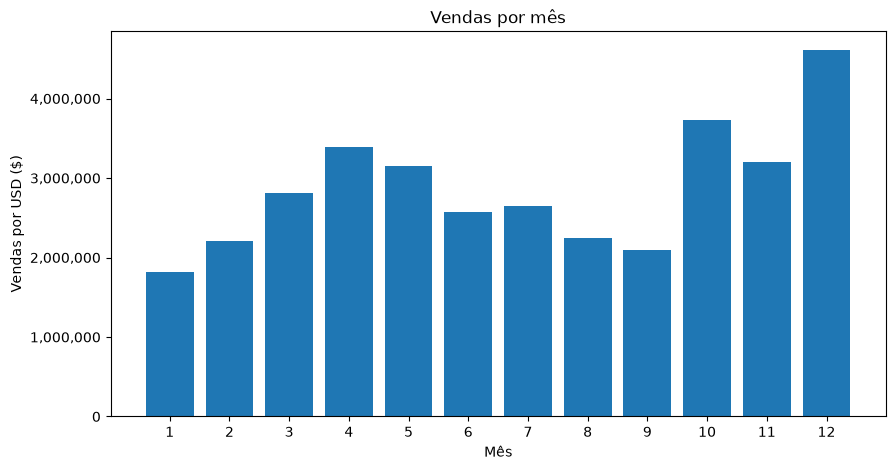

In [18]:
months = range(1,13)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(months, resultados['Sales'])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xticks(months)
ax.set_xlabel('Mês')
ax.set_ylabel('Vendas por USD ($)')
ax.set_title('Vendas por mês')
plt.show()

## Analisando as cidades com os maiores números de vendas

#### Criando uma coluna de Cidade e Estado

In [19]:
df_completo['State'] = df_completo['Purchase Address'].str.split(',').str[2].str.strip().str[0:2]
df_completo['City'] = df_completo['Purchase Address'].str.split(',').str[1].str.strip() + ' (' + df_completo['State'] + ')'

In [20]:
# reordenar a coluna City para ficar após Purchase Address
coluna_city = df_completo.pop('City')
df_completo.insert(7, 'City', coluna_city)
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Sales,Order Date,Purchase Address,City,Month,State
0,176558,USB-C Charging Cable,2,11.95,23.90,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",Dallas (TX),4,TX
1,176559,Bose SoundSport Headphones,1,99.99,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",Boston (MA),4,MA
2,176560,Google Phone,1,600.00,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA
3,176560,Wired Headphones,1,11.99,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA
4,176561,Wired Headphones,1,11.99,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",Los Angeles (CA),4,CA


#### Agrupando os dados de vendas pelas cidades

In [21]:
resultados_cidades = df_completo.groupby('City')[[ 'Sales']].sum()
resultados_cidades

,Sales
City,
Atlanta (GA),2795498.58
Austin (TX),1819581.75
Boston (MA),3661642.01
Dallas (TX),2767975.40
Los Angeles (CA),5452570.80
New York City (NY),4664317.43
Portland (ME),449758.27
Portland (OR),1870732.34
San Francisco (CA),8262203.91


#### Criando um gráfico de barras para visualizar as vendas por cidade

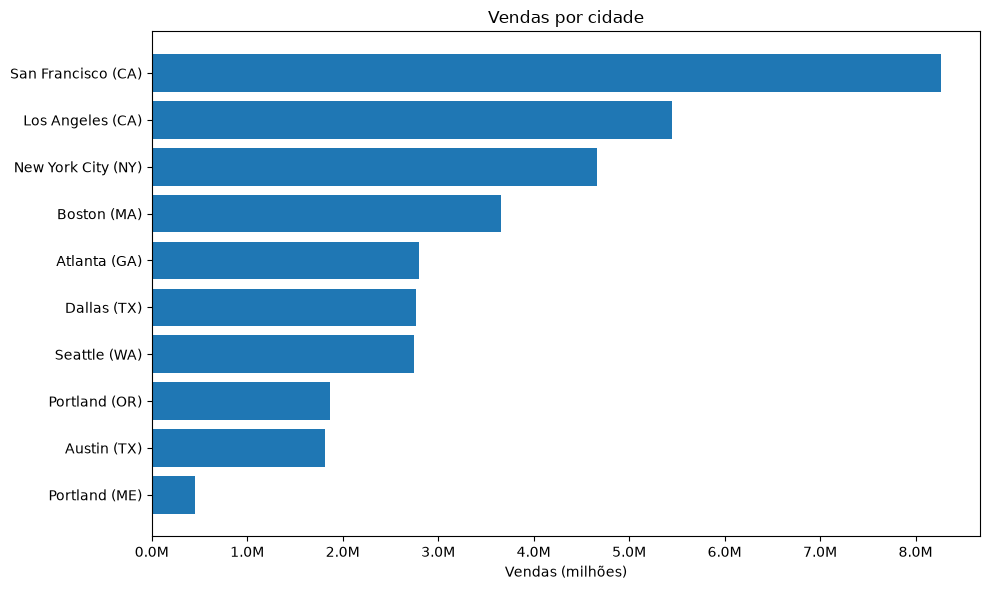

In [22]:
vendas = resultados_cidades['Sales'].sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(vendas.index, vendas.values)
ax.set_title('Vendas por cidade')
ax.set_xlabel('Vendas (milhões)')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

## Analisando os horários com os maiores números de pedidos

In [23]:
df_completo['Hour'] = df_completo['Order Date'].dt.hour
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Sales,Order Date,Purchase Address,City,Month,State,Hour
0,176558,USB-C Charging Cable,2,11.95,23.90,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",Dallas (TX),4,TX,8
1,176559,Bose SoundSport Headphones,1,99.99,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",Boston (MA),4,MA,22
2,176560,Google Phone,1,600.00,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,14
3,176560,Wired Headphones,1,11.99,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,14
4,176561,Wired Headphones,1,11.99,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,9


#### Agrupando os dados de pedidos pelo horário

In [24]:
pedidos_hora = df_completo.groupby('Hour')['Order ID'].nunique()
pedidos_hora

Hour
0      3758
1      2255
2      1196
3       804
4       814
5      1259
6      2375
7      3836
8      6036
9      8404
10    10492
11    11882
12    12082
13    11682
14    10522
15     9761
16     9960
17    10476
18    11761
19    12377
20    11763
21    10499
22     8453
23     5990
Name: Order ID, dtype: int64

#### Criando um gráfico de linhas para visualizar os pedidos por horário

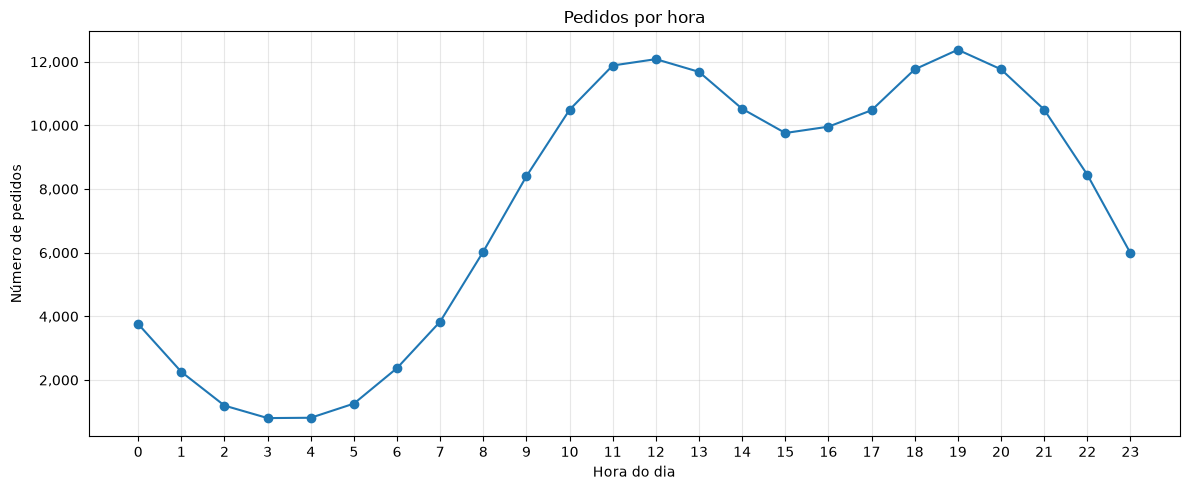

In [25]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pedidos_hora.index, pedidos_hora.values, marker='o')
ax.set_xticks(range(0, 24))
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Número de pedidos')
ax.set_title('Pedidos por hora')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Analisando os produtos que são vendidos juntos com maior frequência

In [26]:
df_completo.head()

,Order ID,Product,Quantity Ordered,Price Each,Sales,Order Date,Purchase Address,City,Month,State,Hour
0,176558,USB-C Charging Cable,2,11.95,23.90,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",Dallas (TX),4,TX,8
1,176559,Bose SoundSport Headphones,1,99.99,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",Boston (MA),4,MA,22
2,176560,Google Phone,1,600.00,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,14
3,176560,Wired Headphones,1,11.99,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,14
4,176561,Wired Headphones,1,11.99,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,9


#### Criação de um outro df para encontrar os produtos que mais saem juntos

In [54]:
df_dup = df_completo[df_completo['Order ID'].duplicated(keep=False)]
df_dup.head()

,Order ID,Product,Quantity Ordered,Price Each,Sales,Order Date,Purchase Address,City,Month,State,Hour
2,176560,Google Phone,1,600.00,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,14
3,176560,Wired Headphones,1,11.99,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,14
17,176574,Google Phone,1,600.00,600.00,2019-04-03 19:42:00,"20 Hill St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,19
18,176574,USB-C Charging Cable,1,11.95,11.95,2019-04-03 19:42:00,"20 Hill St, Los Angeles, CA 90001",Los Angeles (CA),4,CA,19
29,176585,Bose SoundSport Headphones,1,99.99,99.99,2019-04-07 11:31:00,"823 Highland St, Boston, MA 02215",Boston (MA),4,MA,11


In [28]:
# juntar os pedidos em uma só linha
df_dup['Agrupado'] = df_dup.groupby('Order ID')['Product'].transform(lambda x: ', '.join(x))
df_dup = df_dup[['Order ID', 'Agrupado']].drop_duplicates()
df_dup.head(10)

,Order ID,Agrupado
2,176560,"Google Phone, Wired Headphones"
17,176574,"Google Phone, USB-C Charging Cable"
29,176585,"Bose SoundSport Headphones, Bose SoundSport He..."
31,176586,"AAA Batteries (4-pack), Google Phone"
118,176672,"Lightning Charging Cable, USB-C Charging Cable"
128,176681,"Apple Airpods Headphones, ThinkPad Laptop"
137,176689,"Bose SoundSport Headphones, AAA Batteries (4-p..."
188,176739,"34in Ultrawide Monitor, Google Phone"
224,176774,"Lightning Charging Cable, USB-C Charging Cable"
232,176781,"iPhone, Lightning Charging Cable"


In [33]:
contagem = Counter()

for produto in df_dup['Agrupado']:
    lista = produto.split(', ')
    contagem.update(Counter(combinations(sorted(lista), 2)))
    
for par, valor in contagem.most_common(10):
    print(par, valor)

('Lightning Charging Cable', 'iPhone') 1015
('Google Phone', 'USB-C Charging Cable') 999
('Wired Headphones', 'iPhone') 462
('Google Phone', 'Wired Headphones') 423
('Apple Airpods Headphones', 'iPhone') 373
('USB-C Charging Cable', 'Vareebadd Phone') 368
('Bose SoundSport Headphones', 'Google Phone') 228
('USB-C Charging Cable', 'Wired Headphones') 205
('Vareebadd Phone', 'Wired Headphones') 149
('Lightning Charging Cable', 'Wired Headphones') 129


## Analisando os produtos mais vendidos

In [50]:
mais_vendidos = df_completo.groupby('Product')['Quantity Ordered'].sum().sort_values()
mais_vendidos

Product
LG Dryer                        646
LG Washing Machine              666
Vareebadd Phone                2068
20in Monitor                   4129
ThinkPad Laptop                4130
Macbook Pro Laptop             4728
Flatscreen TV                  4819
Google Phone                   5532
34in Ultrawide Monitor         6199
27in 4K Gaming Monitor         6244
iPhone                         6849
27in FHD Monitor               7550
Bose SoundSport Headphones    13457
Apple Airpods Headphones      15661
Wired Headphones              20557
Lightning Charging Cable      23217
USB-C Charging Cable          23975
AA Batteries (4-pack)         27635
AAA Batteries (4-pack)        31017
Name: Quantity Ordered, dtype: int64

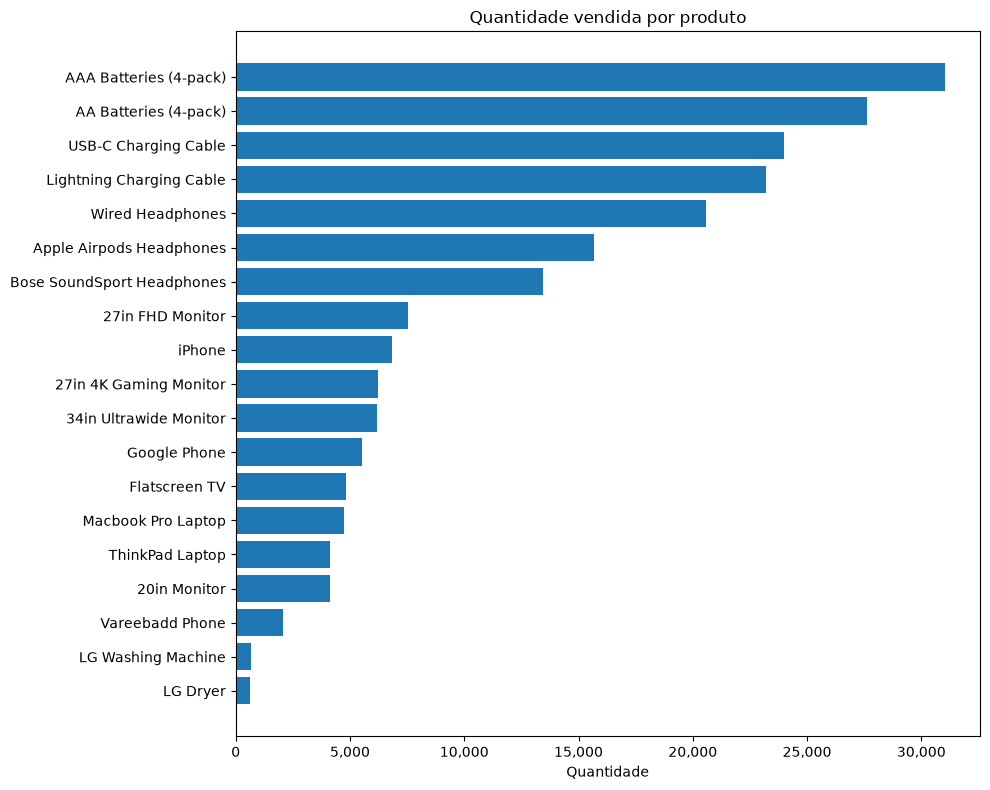

In [53]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(mais_vendidos.index, mais_vendidos.values)
ax.set_title('Quantidade vendida por produto')
ax.set_xlabel('Quantidade')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()